In [1]:
# NOTE:each trial referes to a row in the df (not trial_id)
# this only includes the 2025 one
# some exploration of finding the release frame (using that we can take the last N frames from that and do our feature extraction etc)

In [2]:
import json
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import glob

In [3]:
# download and unzip data from SPL
!wget -q https://github.com/Sport-Performance-Lab/SPL-Open-Data/archive/refs/heads/main.zip
!unzip -q main.zip
!rm -rf main.zip

In [4]:
df = pd.DataFrame(json.load(open(f)) for f in glob.glob(f"SPL-Open-Data-main/basketball/freethrow/data/2025-12-18/*/*.json"))
df

,sampling_rate,trial_date,participant_id,trial_id,result,landing_x,landing_y,entry_angle,tracking
0,60,2025-12-18,P0002,T0092,missed,-8.09,14.61,47.26,"[{'frame': 0, 'time': 0, 'data': {'ball': [28...."
1,60,2025-12-18,P0002,T0004,missed,-4.34,11.35,45.02,"[{'frame': 0, 'time': 0, 'data': {'ball': [28...."
2,60,2025-12-18,P0002,T0016,made,-2.41,7.59,44.43,"[{'frame': 0, 'time': 0, 'data': {'ball': [28...."
3,60,2025-12-18,P0002,T0074,made,-4.75,17.17,42.38,"[{'frame': 0, 'time': 0, 'data': {'ball': [27...."
4,60,2025-12-18,P0002,T0053,made,0.75,7.37,45.02,"[{'frame': 0, 'time': 0, 'data': {'ball': [28...."
...,...,...,...,...,...,...,...,...,...
453,60,2025-12-18,P0001,T0088,made,-0.75,13.83,41.34,"[{'frame': 0, 'time': 0, 'data': {'ball': [28...."
454,60,2025-12-18,P0001,T0045,made,2.38,12.96,42.79,"[{'frame': 0, 'time': 0, 'data': {'ball': [28...."
455,60,2025-12-18,P0001,T0064,missed,-5.28,16.39,41.77,"[{'frame': 0, 'time': 0, 'data': {'ball': [28...."
456,60,2025-12-18,P0001,T0032,made,-5.45,9.14,45.62,"[{'frame': 0, 'time': 0, 'data': {'ball': [28...."


In [5]:
BALL_WIDTH = 0.79 # diameter of a basketball, in feet

def release_frame(trial):
    frames = trial["tracking"]

    ball = np.array([f["data"]["ball"] for f in frames], dtype=float)

    right_wrist = np.array([f["data"]["player"]["RIGHT_WRIST"] for f in frames], dtype=float)
    left_wrist = np.array([f["data"]["player"]["LEFT_WRIST"] for f in frames], dtype=float)

    ball_left_wrist_dist = np.linalg.norm(ball - left_wrist, axis=-1)
    ball_right_wrist_dist = np.linalg.norm(ball - right_wrist, axis=-1)

    gap = np.fmin(ball_left_wrist_dist, ball_right_wrist_dist)

    # last frame where the ball is within one ball-width of a wrist
    return int(np.flatnonzero(gap <= BALL_WIDTH)[-1])

def plot_release_frames():
  frames = []
  for i in range(len(df)):
    frames.append(release_frame(df.loc[i]))

  plt.xlabel("shot (row in df)");
  plt.ylabel("release frame")
  plt.scatter(range(len(frames)), frames, s=8, c=df.participant_id.astype("category").cat.codes)

def find_release_frames_outliers(df, max_off_seconds=0.5, fps=60):
    release = df.apply(release_frame, axis=1)
    usual = release.groupby(df.participant_id).transform("median")
    too_far = abs(release - usual) > max_off_seconds * fps
    return df[too_far]

def plot_shot(trial):
    frames = trial["tracking"]
    ball = np.array([f["data"]["ball"] for f in frames], float)

    for wrist_name in ["RIGHT_WRIST", "LEFT_WRIST"]:
        wrist = np.array([f["data"]["player"][wrist_name] for f in frames], float)
        plt.plot(np.linalg.norm(ball - wrist, axis=1), label=wrist_name)

    release = release_frame(trial)
    plt.axvline(release, color="red", ls="--", label=f"release ({release})")

    plt.title(f"{trial['participant_id']} {trial['trial_id']}")
    plt.xlabel("frame")
    plt.ylabel("ball to wrist (ft)")
    plt.legend()
    plt.show()

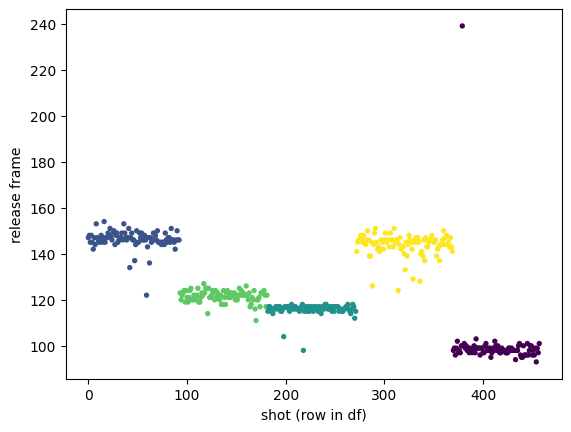

In [6]:
plot_release_frames()

In [7]:
find_release_frames_outliers(df)

,sampling_rate,trial_date,participant_id,trial_id,result,landing_x,landing_y,entry_angle,tracking
379,60,2025-12-18,P0001,T0036,missed,0.59,-0.57,46.06,"[{'frame': 0, 'time': 0, 'data': {'ball': [28...."


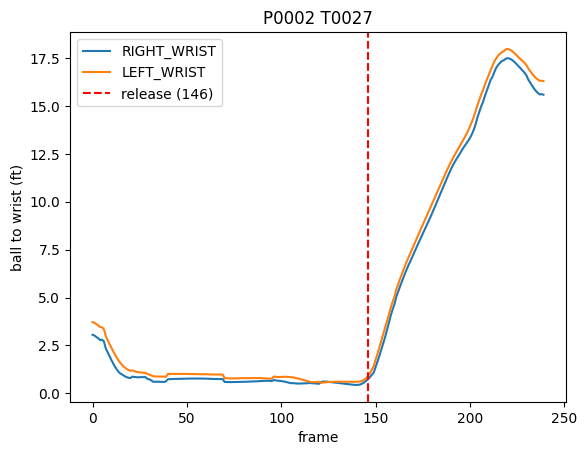

In [8]:
plot_shot(df.loc[10]) # put any trial

In [9]:
HAND_LOOKBACK_SECONDS = 0.10
HAND_DISTANCE_MARGIN_FT = 0.05
MIN_HAND_FRAMES = 3
MIN_TRIAL_AGREEMENT = 0.70

WINDOW_SECONDS = 0.50
RELEASE_BUFFER_SECONDS = 0.05


def point_or_nan(frame, name):
    try:
        data = frame["data"]
        value = data["ball"] if name == "ball" else data["player"][name]
        point = np.asarray(value, dtype=float)
        if point.shape == (3,) and np.isfinite(point).all():
            return point
    except (KeyError, TypeError, ValueError):
        pass
    return np.full(3, np.nan)


def wrist_distances(trial):
    frames = trial["tracking"]
    ball = np.array([point_or_nan(f, "ball") for f in frames]).reshape(-1, 3)
    right = np.array([
        point_or_nan(f, "RIGHT_WRIST") for f in frames
    ]).reshape(-1, 3)
    left = np.array([
        point_or_nan(f, "LEFT_WRIST") for f in frames
    ]).reshape(-1, 3)

    return (
        np.linalg.norm(ball - right, axis=1),
        np.linalg.norm(ball - left, axis=1),
    )


def frame_intervals(seconds, fps):
    return max(1, int(np.ceil(seconds * fps - 1e-9)))


def inspect_shot(trial):
    row = {
        "release_pos": None,
        "trial_hand_vote": "UNKNOWN",
        "hand_frames": 0,
        "trial_hand_agreement": np.nan,
        "window_start_pos": None,
        "window_stop_pos": None,  # Exclusive: use tracking[start:stop].
        "window_span_seconds": np.nan,
        "release_buffer_seconds": np.nan,
        "window_valid": False,
        "window_reason": "no_release_candidate",
    }

    try:
        fps = float(trial["sampling_rate"])
    except (KeyError, TypeError, ValueError):
        fps = np.nan

    if not np.isfinite(fps) or fps <= 0:
        row["window_reason"] = "invalid_sampling_rate"
        return row

    right, left = wrist_distances(trial)

    # Same release heuristic as the original notebook.
    # Later recontact with a wrist can still fool this rule.
    candidates = np.flatnonzero(np.fmin(right, left) <= BALL_WIDTH)
    if len(candidates) == 0:
        return row

    release = int(candidates[-1])
    row["release_pos"] = release

    # Compare wrists shortly before release.
    start = max(
        0, release - frame_intervals(HAND_LOOKBACK_SECONDS, fps) + 1
    )
    r = right[start:release + 1]
    l = left[start:release + 1]

    informative = (
        np.isfinite(r)
        & np.isfinite(l)
        & (np.minimum(r, l) <= BALL_WIDTH)
        & (np.abs(r - l) >= HAND_DISTANCE_MARGIN_FT)
    )

    right_votes = int(np.sum(informative & (r < l)))
    left_votes = int(np.sum(informative & (l < r)))
    count = right_votes + left_votes
    agreement = max(right_votes, left_votes) / count if count else np.nan

    row["hand_frames"] = count
    row["trial_hand_agreement"] = agreement

    if count >= MIN_HAND_FRAMES and agreement >= MIN_TRIAL_AGREEMENT:
        row["trial_hand_vote"] = "RIGHT" if right_votes > left_votes else "LEFT"

    # Window spans at least 0.50 seconds and ends at least 0.05 seconds
    # before estimated release. At 60 fps this gives 31 samples.
    end = release - frame_intervals(RELEASE_BUFFER_SECONDS, fps)
    start = end - frame_intervals(WINDOW_SECONDS, fps)

    if start < 0:
        row["window_reason"] = "insufficient_pre_release_history"
        return row

    # Timing assumes regularly sampled frames
    frames = trial["tracking"]
    frame_ids = [f.get("frame") for f in frames[start:release + 1]]
    if any(value is not None for value in frame_ids):
        try:
            ids = np.asarray(frame_ids, dtype=float)
            consecutive = (
                np.isfinite(ids).all() and np.all(np.diff(ids) == 1)
            )
        except (TypeError, ValueError):
            consecutive = False

        if not consecutive:
            row["window_reason"] = "missing_or_nonconsecutive_frame_ids"
            return row

    row.update({
        "window_start_pos": start,
        "window_stop_pos": end + 1,
        "window_span_seconds": (end - start) / fps,
        "release_buffer_seconds": (release - end) / fps,
        "window_valid": True,
        "window_reason": "ok",
    })
    return row

In [15]:
hand_results = []

for _, trial in df.iterrows():
    result = inspect_shot(trial)

    hand_results.append({
        "participant_id": trial["participant_id"],
        "trial_id": trial["trial_id"],
        "hand_vote": result["trial_hand_vote"],
        "agreement": result["trial_hand_agreement"],
        "frames_used": result["hand_frames"],
    })

hand_results = pd.DataFrame(hand_results)
display(hand_results)
print("Left-hand votes:", (hand_results["hand_vote"] == "LEFT").sum())

,participant_id,trial_id,hand_vote,agreement,frames_used
0,P0002,T0092,RIGHT,1.0,6
1,P0002,T0004,RIGHT,1.0,5
2,P0002,T0016,RIGHT,1.0,6
3,P0002,T0074,UNKNOWN,1.0,2
4,P0002,T0053,RIGHT,1.0,6
...,...,...,...,...,...
453,P0001,T0088,RIGHT,1.0,6
454,P0001,T0045,RIGHT,1.0,6
455,P0001,T0064,RIGHT,1.0,6
456,P0001,T0032,RIGHT,1.0,6


Left-hand votes: 12
